# Principal Component Analysis for Galaxy Images

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 10 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://statml.org/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

In the previous chapters we studied supervised learning with regression and classification. We now turn to unsupervised learning, and we begin with one of the most basic and widely used methods, principal component analysis (PCA). Astronomical data are often high-dimensional, and this makes it hard to find meaningful structure. A sky survey produces images with thousands of pixels or more. A spectrum has thousands of wavelength channels, and a light curve from a time-domain survey has hundreds of measurements.

PCA addresses this curse of dimensionality, the difficulty of finding structure in many dimensions. It finds the directions of maximum variance in the data and projects the data onto a lower-dimensional subspace that keeps the most important information. In this way PCA can reveal the hidden structure of a complex data set. This structure can guide the search for the physical processes behind the data, but PCA does not identify them by itself.

Consider galaxy morphology, which carries information about the formation history, the stellar populations and the evolutionary state of a galaxy. Galaxies look very different from each other, but their variation may follow a few basic shapes. PCA looks for such shapes in the data, without a prior choice of the features that matter most. The shapes can show, for example, the elongation of a galaxy and the concentration of its light.

This approach differs from parametric methods, which fit the brightness of a galaxy with a function of the radius, such as a Sérsic profile. These models are very useful, but they limit the analysis to features that we choose in advance. PCA uses only the data, and it can reveal structure that we did not expect. This matters more for fainter objects and subtler effects, where our physical intuition is less reliable.

PCA has many applications in astronomy beyond galaxy morphology. In spectroscopy, it can find the main modes of spectral variation. It can reduce thousands of wavelength channels to a handful of principal components, which are called eigenspectra. These components can relate to the stellar temperature and the metallicity, although they often mix the two (Section 10.9). In time-domain astronomy, PCA helps to separate the intrinsic variability from the systematic effects in light curves.

In this tutorial we apply PCA to images of galaxies. We look at the principal components as images, at the variance that they keep and at the reconstructions from a few components.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Linear algebra, with matrices, eigenvalues, eigenvectors and matrix decompositions
- Python programming with NumPy arrays and matplotlib plots
- Statistics, with covariance matrices, variance and correlation

### Learning Objectives

After this tutorial you can do the following.

- Implement PCA with the singular value decomposition (SVD) and relate the singular values to the eigenvalues of the covariance matrix
- Display the principal components of images as eigengalaxies and interpret them
- Measure the variance that a number of components keeps, relate it to the reconstruction error and choose the reduced dimension
- Project data into a space of lower dimension and reconstruct them, and judge the trade-off between compression and accuracy
- Apply PCA to real galaxy images and explain why it can separate coherent structure from noise

We begin by importing the libraries and setting the plot style.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

%matplotlib inline

## Understanding the Data: Galaxy Images from Modern Surveys

In this tutorial we use a curated data set of galaxy cutouts. They come from the Sloan Digital Sky Survey (SDSS) images of Galaxy Zoo 2, as in [Ma et al. 2026](https://ui.adsabs.harvard.edu/abs/2026ApJS..282...25M/abstract). The galaxy cutouts have the following properties.

- **Subsampled.** We subsample the images to 64 × 64 pixels, so the computation is tractable and the morphological features remain.
- **Normalized.** The pixel values lie between 0 and 1.

Each 64 × 64 image has 4,096 pixels, so each galaxy is a point in a space of 4,096 dimensions.

We load the images and look at their shape and pixel values.

In [2]:
# Load the galaxy image dataset
galaxy_images = np.load('../data/dataset_images_galaxy.npy')

# Print the shape (galaxies, pixels) and the pixel value statistics
print("Shape of the galaxy images =", galaxy_images.shape)
print(f"Pixel values: minimum = {np.min(galaxy_images):.3f}, maximum = {np.max(galaxy_images):.3f}, "
      f"mean = {np.mean(galaxy_images):.3f}")

Shape of the galaxy images = (1500, 4096)
Pixel values: minimum = 0.000, maximum = 0.899, mean = 0.065


Before we reduce the dimension, we look at the raw data. The variety of the galaxies helps us to interpret the principal components that we extract. Galaxy morphology covers a wide range, from smooth elliptical galaxies with concentrated light profiles to grand-design spirals with extended disks and prominent arms.

The function below shows many galaxy images in a grid. We use it throughout this tutorial to compare the original images with their PCA reconstructions.

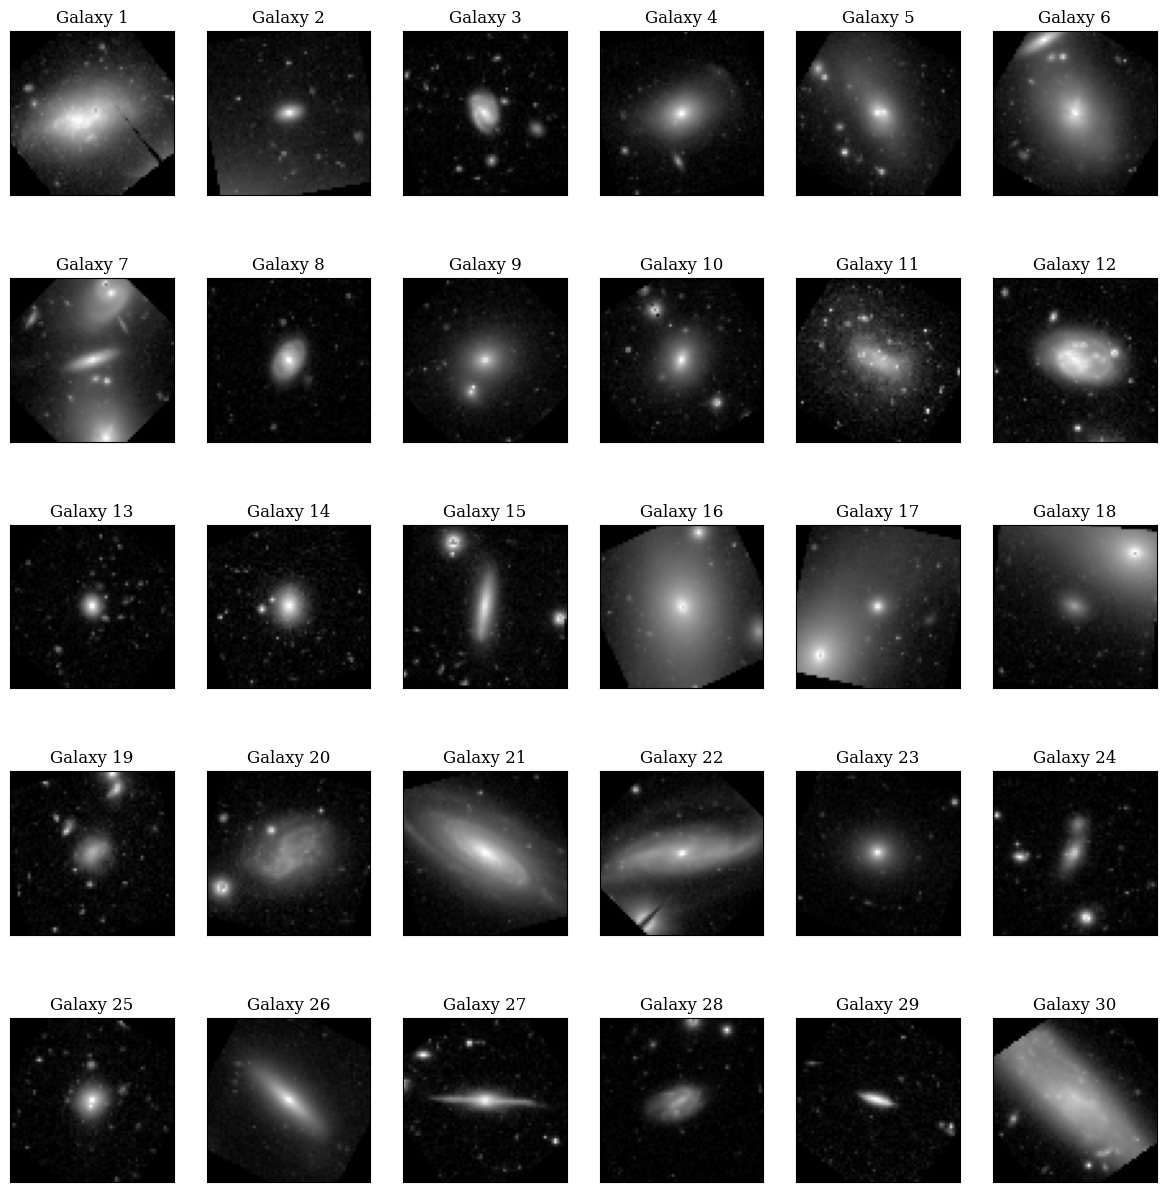

In [3]:
def plot_gallery(images, titles, h, w, n_row=2, n_col=6):
    """Plot the rows of `images` as h x w images in an n_row x n_col grid."""

    # Check that there are enough images and titles for the grid
    assert len(images) >= n_row * n_col
    assert len(titles) >= n_row * n_col

    # Set up the figure
    plt.figure(figsize=(1.95 * n_col, 2.6 * n_row))
    plt.subplots_adjust(bottom=0, left=.01, right=.99, top=.90, hspace=.35)

    # Loop to populate the gallery
    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)

        # Reshape the flattened image data to 2D and plot it
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)

        # Add the title and remove the axis ticks
        plt.title(titles[i], size=12)
        plt.xticks(())
        plt.yticks(())

    plt.show()

# Display a sample of galaxy images
plot_gallery(galaxy_images, [f"Galaxy {i + 1}" for i in range(30)], 64, 64, 5, 6)

The galaxies differ in size, shape and brightness. Some cutouts hold bright neighbors, and some have black corners and tilted edges at the border of the image frame.

## The Mathematics of PCA

The galaxies share some patterns, such as a bright center. PCA finds such patterns. It transforms the galaxy images into a new coordinate system. The axes of this system, the principal components, are ordered by the amount of variance that they carry. This transformation shows the main structure of galaxy morphology and lets us reduce the dimension.

### Step 1: Centering the Data

The first step of PCA is to center the data by subtracting the mean. The data set has $N$ images $\{\mathbf{x}_i\}_{i=1}^N$, and each image is a row vector in $\mathbb{R}^D$ with $D = 4096$ pixels. We compute the mean galaxy image

$$\overline{\mathbf{x}} = \frac{1}{N}\sum_{i=1}^{N}\mathbf{x}_i.$$

This mean image is the "average galaxy" of the sample. Centering makes the principal components describe the variation around this average and not the mean signal itself. We subtract the mean from every image,

$$\mathbf{x}_i \leftarrow \mathbf{x}_i - \overline{\mathbf{x}}.$$

### Step 2: Computing the Singular Value Decomposition

PCA needs the eigenvectors of the covariance matrix $\mathbf{S} = (1/N)\mathbf{X}^T\mathbf{X}$ of the centered data matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$. These eigenvectors are the principal components, and the variance along each one is its eigenvalue (Section 10.4). We do not form $\mathbf{S}$, because it has $4096 \times 4096$ entries and its eigenvectors need more operations than the SVD of $\mathbf{X}$ when $N < D$ (Section 10.8). Our data have $N = 1500$ galaxies and $D = 4096$ pixels, so $N < D$. The SVD gives the same eigenvectors,

$$\mathbf{X} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^T.$$

Here $\mathbf{U} \in \mathbb{R}^{N \times N}$ holds the left singular vectors, $\boldsymbol{\Sigma} \in \mathbb{R}^{N \times D}$ is a rectangular diagonal matrix of singular values, and $\mathbf{V} \in \mathbb{R}^{D \times D}$ holds the right singular vectors. The columns of $\mathbf{V}$ are the principal components, the directions in pixel space along which the galaxy images vary most.

### Step 3: Understanding the Variance Decomposition

The singular values in $\boldsymbol{\Sigma}$ give the eigenvalues of $\mathbf{S}$. For component $m$, the variance is the eigenvalue (Section 10.8)

$$\lambda_m = \frac{\sigma_m^2}{N},$$

where $\sigma_m$ is the $m$-th singular value. This relation lets us measure how much of the total variation in galaxy morphology each component carries. It guides our choice of how many components to keep.

### Step 4: Dimensionality Reduction

To reduce the galaxy images from 4096 dimensions to $M$ dimensions, we project them onto the first $M$ principal components,

$$\mathbf{Z} = \mathbf{X}\mathbf{V}_M = \mathbf{U}_M\boldsymbol{\Sigma}_M,$$

where $\mathbf{V}_M$ holds the first $M$ columns of $\mathbf{V}$. Each row of $\mathbf{Z}$ is an $M$-dimensional representation of a galaxy that keeps the most important morphological information.

We now implement PCA for the galaxy images. We write two functions that use the efficient SVD of NumPy.

1. The function `pca()` runs the complete PCA. It centers the data, computes the SVD and returns the projected data, the principal components and the SVD for later use. The projected data are the coefficients of each galaxy.
2. The function `svd2pca()` lets us try different numbers of components without a new computation of the expensive SVD.

This design lets us see how the reconstruction quality changes with the number of components that we keep.

NumPy's `linalg.svd()` returns $\mathbf{U}$, the singular values as a one-dimensional array and $\mathbf{V}^T$. The principal components are the rows of $\mathbf{V}^T$, which are the columns of $\mathbf{V}$. The option `full_matrices=False` returns only the first $N$ rows of $\mathbf{V}^T$, which is enough because $N < D$ (Section 10.8). The other rows of $\mathbf{V}^T$ belong to zero singular values.

In [4]:
def pca(X, n_pc=2):
    """Compute PCA with the economy-size SVD. Return the coefficients, the first n_pc components, U, Sig and Vt."""

    # Copy the data to avoid modifying the original dataset
    X = X.copy()

    # Center the data by subtracting the mean image
    mean_image = np.mean(X, axis=0)
    X -= mean_image

    # Compute the SVD. The economy size returns only the first N rows of Vt
    U, Sig, Vt = np.linalg.svd(X, full_matrices=False)

    # The first n_pc rows of Vt are the principal components
    components = Vt[:n_pc]

    # Project the data on these components to get the coefficients
    projected = U[:, :n_pc] * Sig[:n_pc]

    return projected, components, U, Sig, Vt

def svd2pca(U, Sig, Vt, n_pc=2):
    """Project on n_pc principal components with a precomputed SVD. Return the coefficients and the components."""

    # Select the first n_pc principal components
    components = Vt[:n_pc]

    # Project the data on these components (the columns of U times the singular values)
    projected = U[:, :n_pc] * Sig[:n_pc]

    return projected, components

## Eigengalaxies: Visualizing Principal Components

When we apply PCA to galaxy images, we can display each principal component as an image, which we call an eigengalaxy. An eigengalaxy shows one mode of variation of the data set. Every galaxy of the sample is the mean galaxy plus a weighted sum of these basic images. Astronomers can look at these images directly.

A component has one weight per pixel, so we reshape it to 64 × 64. Each tile has its own gray scale, from the lowest weight (black) to the highest weight (white). The sign of a whole component is arbitrary. The reconstruction stays the same when the weights and the coefficients of a component both change sign.

PCA works well here because the pixel values of galaxies are correlated. Some distributions of light occur often and others are implausible, so the images do not fill the space of all possible pixel values. PCA finds the directions in pixel space along which the galaxies vary most.

We now compute the first 20 principal components of the galaxy data set and display them. The function `pca()` returns the coefficients of every galaxy and the principal components.

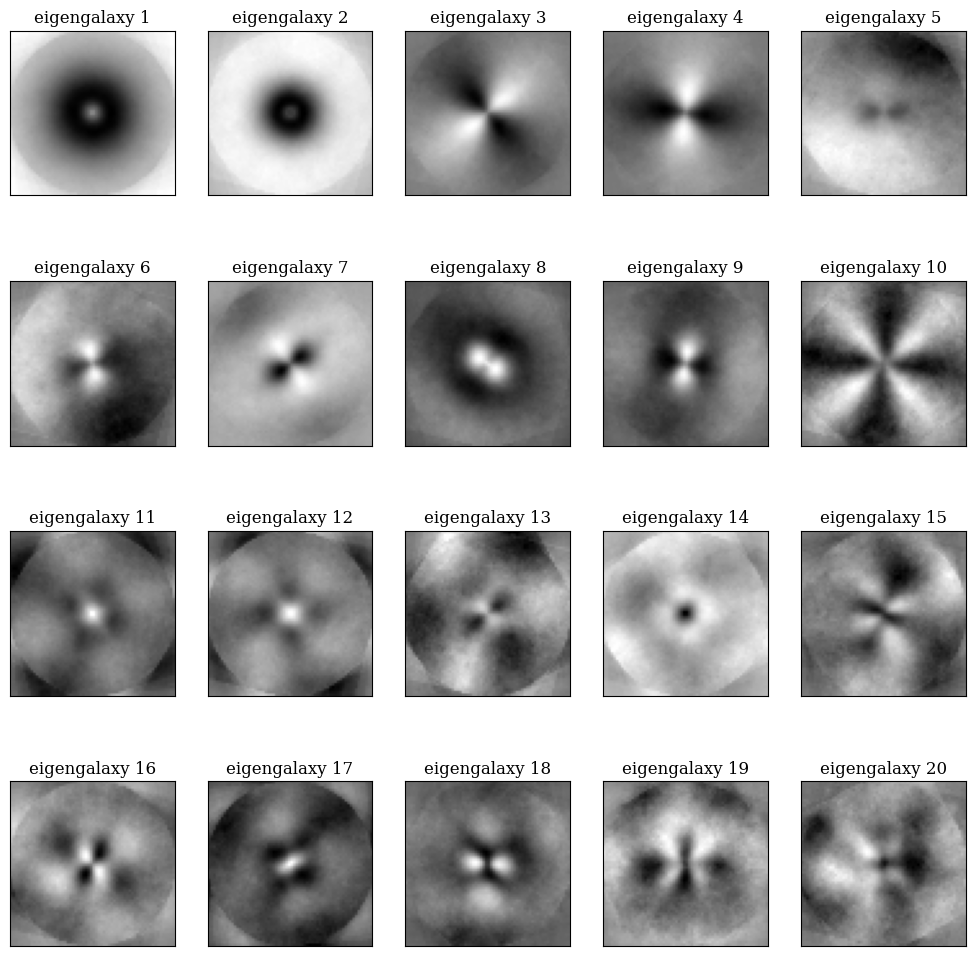

In [5]:
# Set the parameters for PCA and the image shape
h = 64  # Height of images
w = 64  # Width of images
n_components = 20  # Number of principal components to extract

# Perform PCA on galaxy images
Z, P, U, Sig, Vt = pca(galaxy_images, n_pc=n_components)

# Reshape the principal components to visualize them as images
eigengalaxies = P.reshape((n_components, h, w))

# Generate titles for the gallery
eigengalaxy_titles = [f"eigengalaxy {i + 1}" for i in range(eigengalaxies.shape[0])]

# Visualize the first 20 principal components
plot_gallery(eigengalaxies, eigengalaxy_titles, h, w, n_components//5, 5)

The eigengalaxies show a hierarchy in the features that they encode.

**First components (eigengalaxies 1 and 2).** These describe the most dominant variations of the sample. Eigengalaxy 1 is circularly symmetric and has weights of one sign in nearly every pixel, so its coefficient follows the overall brightness of a galaxy. Eigengalaxy 2 is also circularly symmetric, and it encodes the difference between concentrated and extended galaxies.

**Early components (eigengalaxies 3 to 10).** Eigengalaxies 3 and 4 show two quadrupole shapes, each with two bright and two dark lobes. Eigengalaxy 4 is eigengalaxy 3 turned by about 45 degrees. A mix of the two, with the right coefficients, points along any angle, so together they describe the elongation and the orientation of a galaxy. Eigengalaxies 5 to 10 are more complex. Eigengalaxies 7 to 9 have their structure near the center. Eigengalaxy 5 is a broad gradient, and eigengalaxy 10 has eight lobes over the whole image.

**Middle components (eigengalaxies 11 to 20).** The shapes become more complex, and they describe more subtle variations.

These shapes are the ways in which the galaxies differ from the mean galaxy. We read them as modes of variation, which need not match a physical property (Section 10.9).

## Measuring Information Content: Variance Analysis

To decide how many components to keep, we measure how much variance each component carries. A regression has a prediction error that guides the choice of its complexity. PCA has no target and so no prediction error, and the variance of the components guides us instead. In Step 3 the variance along component $m$ is the eigenvalue $\lambda_m = \sigma_m^2/N$, where $N$ is the number of galaxy images.

We first check this relation on the galaxies. The check forms the covariance matrix of the 4,096 pixels once. It compares the five largest eigenvalues of this matrix with $\sigma_m^2/N$.

In [6]:
# Center the images and form the covariance matrix
centered = galaxy_images - np.mean(galaxy_images, axis=0)
covariance = centered.T @ centered / len(galaxy_images)

# Eigenvalues of this symmetric matrix, largest first
covariance_eigenvalues = np.linalg.eigvalsh(covariance)[::-1]

# Compare the five largest with the squared singular values divided by N
print("Covariance matrix:", np.round(covariance_eigenvalues[:5], 4))
print("SVD, sigma^2 / N: ", np.round(Sig[:5]**2 / len(galaxy_images), 4))

Covariance matrix: [13.0422  2.0541  1.0255  0.8811  0.4966]
SVD, sigma^2 / N:  [13.0422  2.0541  1.0255  0.8811  0.4966]


The two lists agree, so the singular values give the eigenvalues without the covariance matrix. The fraction of the total variance that component $m$ explains is

$$\frac{\lambda_m}{\sum_j \lambda_j}.$$

The running sum of these fractions is the explained variance ratio of the first $M$ components (Section 10.7). Plotted against $M$, it is the cumulative variance curve. The curve shows how many components keep a chosen share of the variance. The share that we need depends on the application, because a measurement of galaxy shapes needs more of the information than a fast classification.

We plot the curve with dots at 5, 20 and 50 components. We also print the number of components that reach 80, 90 and 95 percent of the variance.

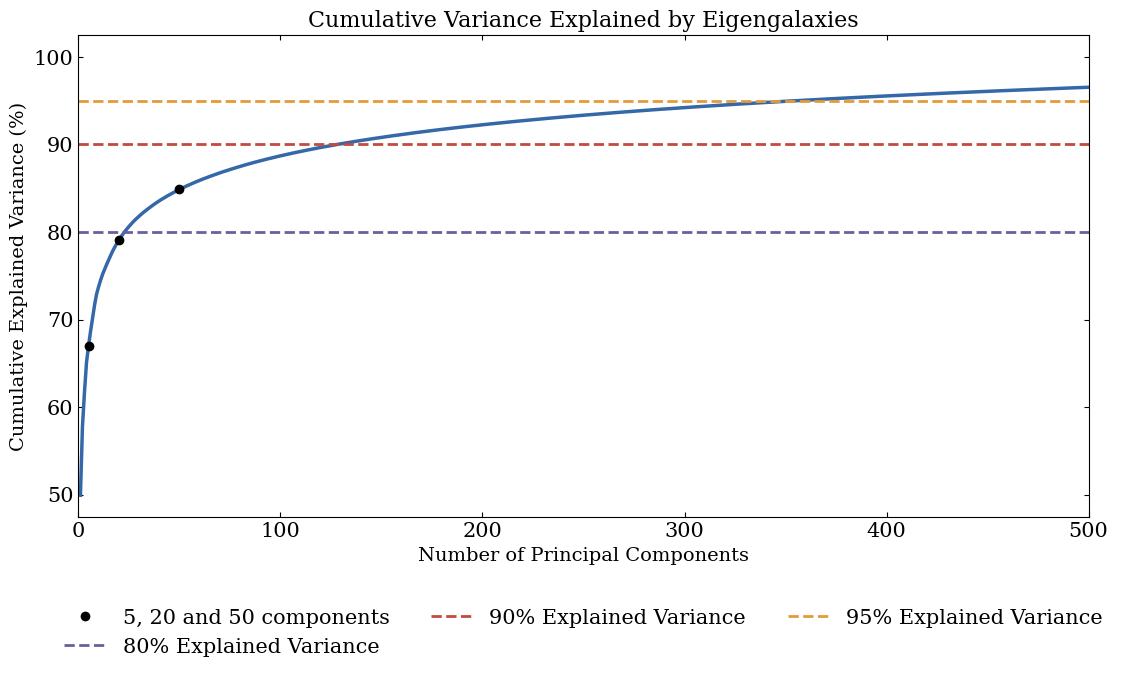

80% of the variance needs 23 components (0.56% of the pixels)
90% of the variance needs 129 components (3.15% of the pixels)
95% of the variance needs 356 components (8.69% of the pixels)


In [7]:
# Calculate eigenvalues from singular values
eigenvalues = (Sig**2) / galaxy_images.shape[0]  # Convert singular values to eigenvalues
cumulative_variance = np.cumsum(eigenvalues) / np.sum(eigenvalues)  # running sum of the variance fractions

# Plot the cumulative explained variance
plt.figure(figsize=(11.9, 7.1))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance * 100, color='C0', linewidth=2.5)

# Mark 5, 20 and 50 components, which we use for the reconstructions below
marked = np.array([5, 20, 50])
plt.plot(marked, cumulative_variance[marked - 1] * 100, 'o', color='k', label='5, 20 and 50 components')  # the index is the number minus 1

# Labels, title and the three reference lines
plt.xlabel('Number of Principal Components', fontsize=14)
plt.ylabel('Cumulative Explained Variance (%)', fontsize=14)
plt.title('Cumulative Variance Explained by Eigengalaxies', fontsize=16)
plt.axhline(y=80, color='C4', linestyle='--', linewidth=2, label='80% Explained Variance')
plt.axhline(y=90, color='C3', linestyle='--', linewidth=2, label='90% Explained Variance')
plt.axhline(y=95, color='C1', linestyle='--', linewidth=2, label='95% Explained Variance')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

# Show the first 500 of the 1500 components
plt.xlim(0, 500)
plt.tight_layout()
plt.show()

# Count the components that reach 80% of the variance (the first index above the threshold, plus 1)
n_components_80 = np.where(cumulative_variance >= 0.8)[0][0] + 1

# Do the same for 90% and 95%
n_components_90 = np.where(cumulative_variance >= 0.9)[0][0] + 1
n_components_95 = np.where(cumulative_variance >= 0.95)[0][0] + 1

# Print the counts and their share of the pixels
for share, count in [(80, n_components_80), (90, n_components_90), (95, n_components_95)]:
    print(f"{share}% of the variance needs {count} components ({count / galaxy_images.shape[1]:.2%} of the pixels)")

The cumulative variance curve rises steeply and then slowly. The first component alone carries about half of the variance. With 23 principal components, which are 0.56% of the 4,096 dimensions, we keep 80% of the total variance of the galaxy sample. The levels of 90% and 95% need 129 and 356 components, many more than the 23 for 80%. The plot shows the first 500 of the 1,500 components, and the curve reaches 100% when it includes all of them.

The steep initial rise is typical of data with structure and strong pixel correlations. For random noise, the variance would spread much more evenly over the components. The remaining 20% of the variance holds smaller details, the peculiarities of individual galaxies and noise.

The curve shows that the galaxy images are highly redundant. It does not show that a few physical processes shape the galaxies, because PCA only finds the directions of large variance (Section 10.9).

## Reconstructing Galaxies from Principal Components

The explained variance says how much variance we keep. The variance that we drop is the average squared reconstruction error (Section 10.1). The reconstruction is therefore the direct test of a dimensionality reduction. We project the galaxy images onto a reduced set of principal components and then reconstruct them. This shows what morphological information the reduction keeps and what it loses.

The reconstruction follows directly from the PCA decomposition. For a galaxy image $\mathbf{x}$, we first subtract the mean, $\mathbf{x}' = \mathbf{x} - \overline{\mathbf{x}}$. The projection onto $M$ principal components gives the coefficients $\mathbf{z} = \mathbf{x}'\mathbf{V}_M$, where $\mathbf{V}_M$ holds the first $M$ columns of the principal component matrix. The reconstruction is then (Section 10.1)

$$\widehat{\mathbf{x}} = \mathbf{z}\mathbf{V}_M^T + \overline{\mathbf{x}} = \mathbf{x}'\mathbf{V}_M\mathbf{V}_M^T + \overline{\mathbf{x}}.$$

The matrix product $\mathbf{V}_M\mathbf{V}_M^T$ is a projection operator. It keeps only the part of the image that lies in the $M$-dimensional subspace of the kept principal components. When $M$ reaches the full dimension, the projection becomes the identity and we recover the original image exactly.

We fit the PCA to all galaxies of the sample and reconstruct the same galaxies. We first compute the reconstructions from 50, 20 and 5 principal components (PCs). We then check their error and show them to see the trade-off.

In [8]:
# Calculate the mean of the original galaxy images
mean_image = np.mean(galaxy_images, axis=0)

# Reconstruct with 50, 20 and 5 principal components
reconstructed = {}
for n_pc in (50, 20, 5):
    galaxy_Z, galaxy_P = svd2pca(U, Sig, Vt, n_pc=n_pc)
    reconstructed[n_pc] = np.dot(galaxy_Z, galaxy_P) + mean_image  # coefficients times components plus the mean

We now check that the dropped variance equals the average squared reconstruction error. The error of one galaxy is the squared distance between the galaxy and its reconstruction, summed over the 4,096 pixels. We average it over the 1,500 galaxies and compare it with the sum of the eigenvalues that we left out.

In [9]:
# Compare the average squared error with the sum of the dropped eigenvalues
for n_pc in (5, 20, 50):
    error = np.mean(np.sum((galaxy_images - reconstructed[n_pc])**2, axis=1))
    print(f"{n_pc} components: error {error:.2f}, dropped variance {np.sum(eigenvalues[n_pc:]):.2f}")

5 components: error 8.63, dropped variance 8.63
20 components: error 5.47, dropped variance 5.47
50 components: error 3.96, dropped variance 3.96


The two numbers agree for each number of components, so the explained variance and the reconstruction error describe the same loss. After the reduction, a galaxy is described by its coefficients, which are its coordinates along the principal components. We take Galaxy 26 and print its first five coefficients. We then add the weighted eigengalaxies to the mean galaxy for 1, 3, 5 and 20 components (Section 10.1).

In [10]:
# Print the first five coefficients of Galaxy 26, the row 25 of the arrays
print("Galaxy 26, coefficients 1 to 5:", np.round(Z[25, :5], 2))

# Add the weighted eigengalaxies to the mean galaxy
build_up = [mean_image + Z[25, :m] @ P[:m] for m in (1, 3, 5, 20)]

Galaxy 26, coefficients 1 to 5: [-2.95 -0.96 -2.59 -0.57 -0.01]


We show Galaxy 26, the mean galaxy and the four partial sums.

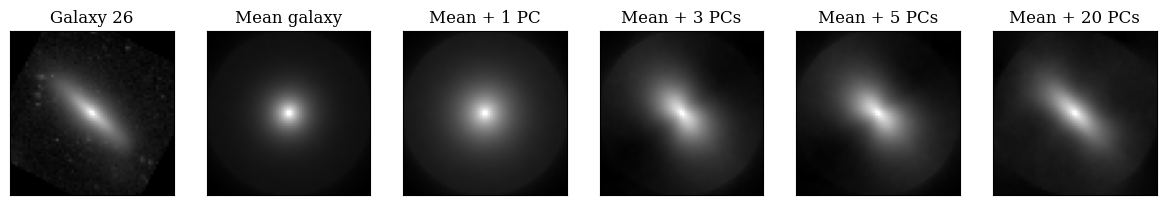

In [11]:
# Show the galaxy, the mean galaxy and the partial sums
images = [galaxy_images[25], mean_image] + build_up
titles = ["Galaxy 26", "Mean galaxy", "Mean + 1 PC", "Mean + 3 PCs", "Mean + 5 PCs", "Mean + 20 PCs"]
plot_gallery(images, titles, 64, 64, 1, 6)

The mean galaxy is a round blob, and the first component keeps it round. The elongation appears with the third component, whose coefficient of $-2.59$ is large. More components make the shape more like the galaxy. The first coefficient is negative, because the weights of eigengalaxy 1 are negative and Galaxy 26 has more light than the mean galaxy.

We now show the first 30 galaxies, and then their reconstructions from 50, 20 and 5 principal components. We look at the elongated galaxies 15, 21, 26 and 30, and at galaxies with neighbors, such as 7, 17 and 18.

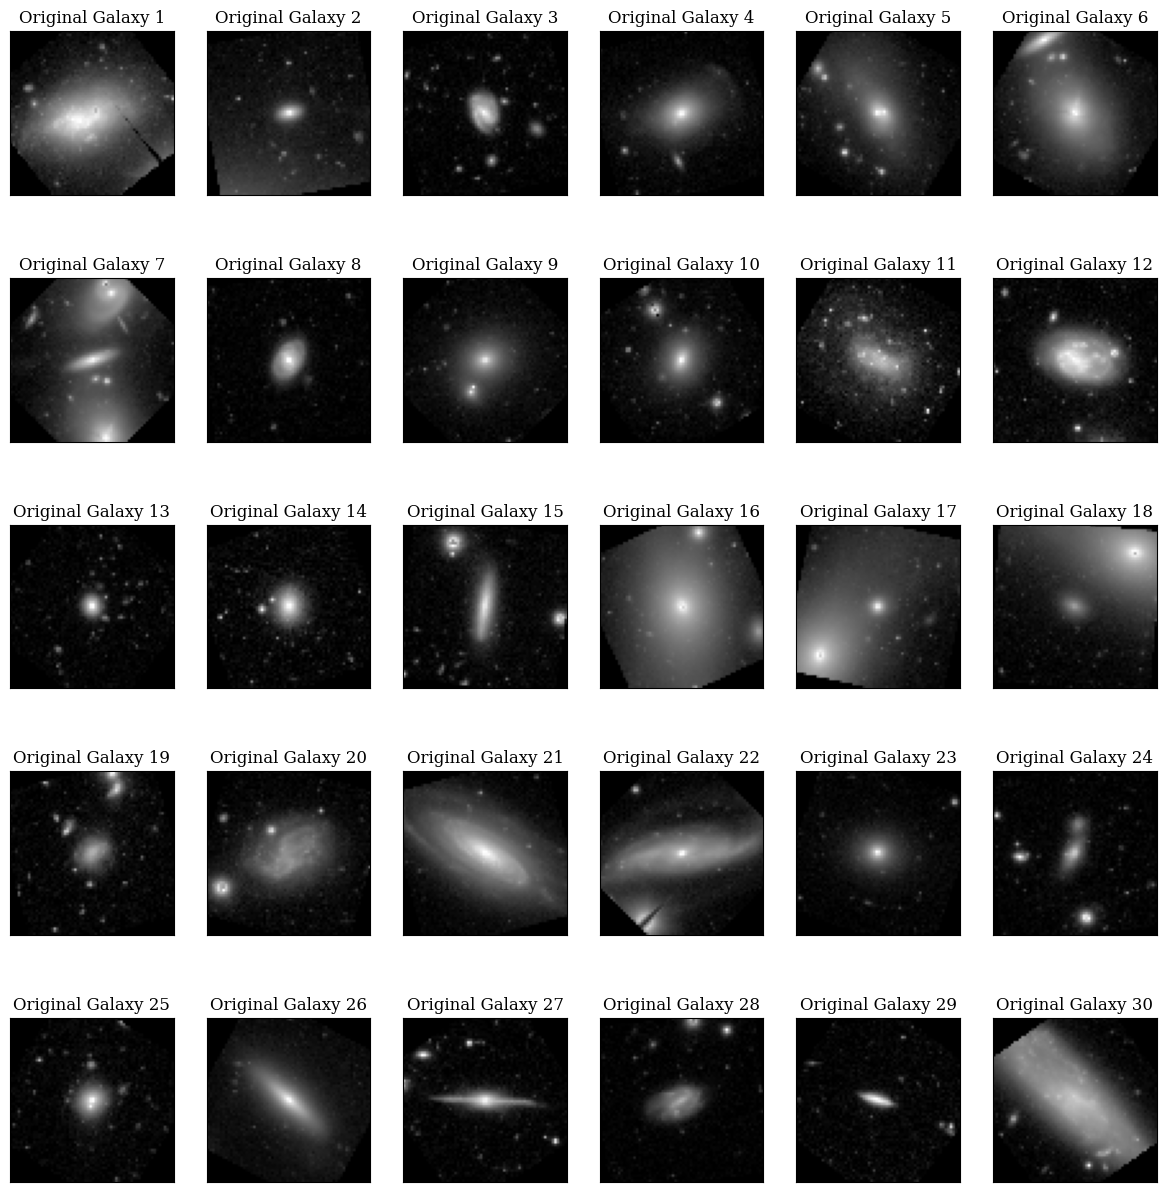

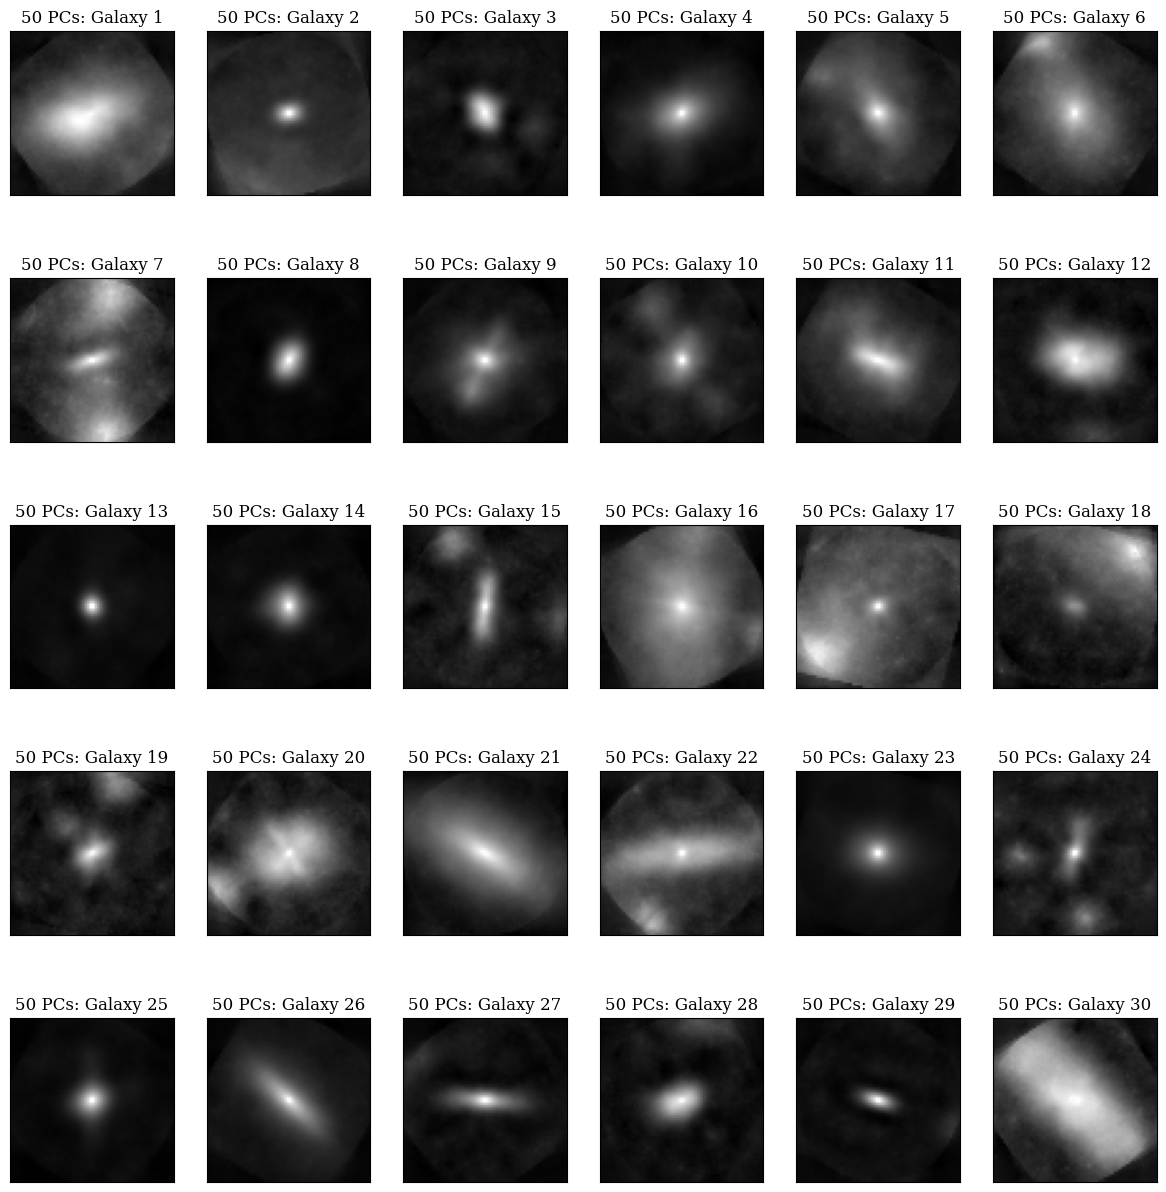

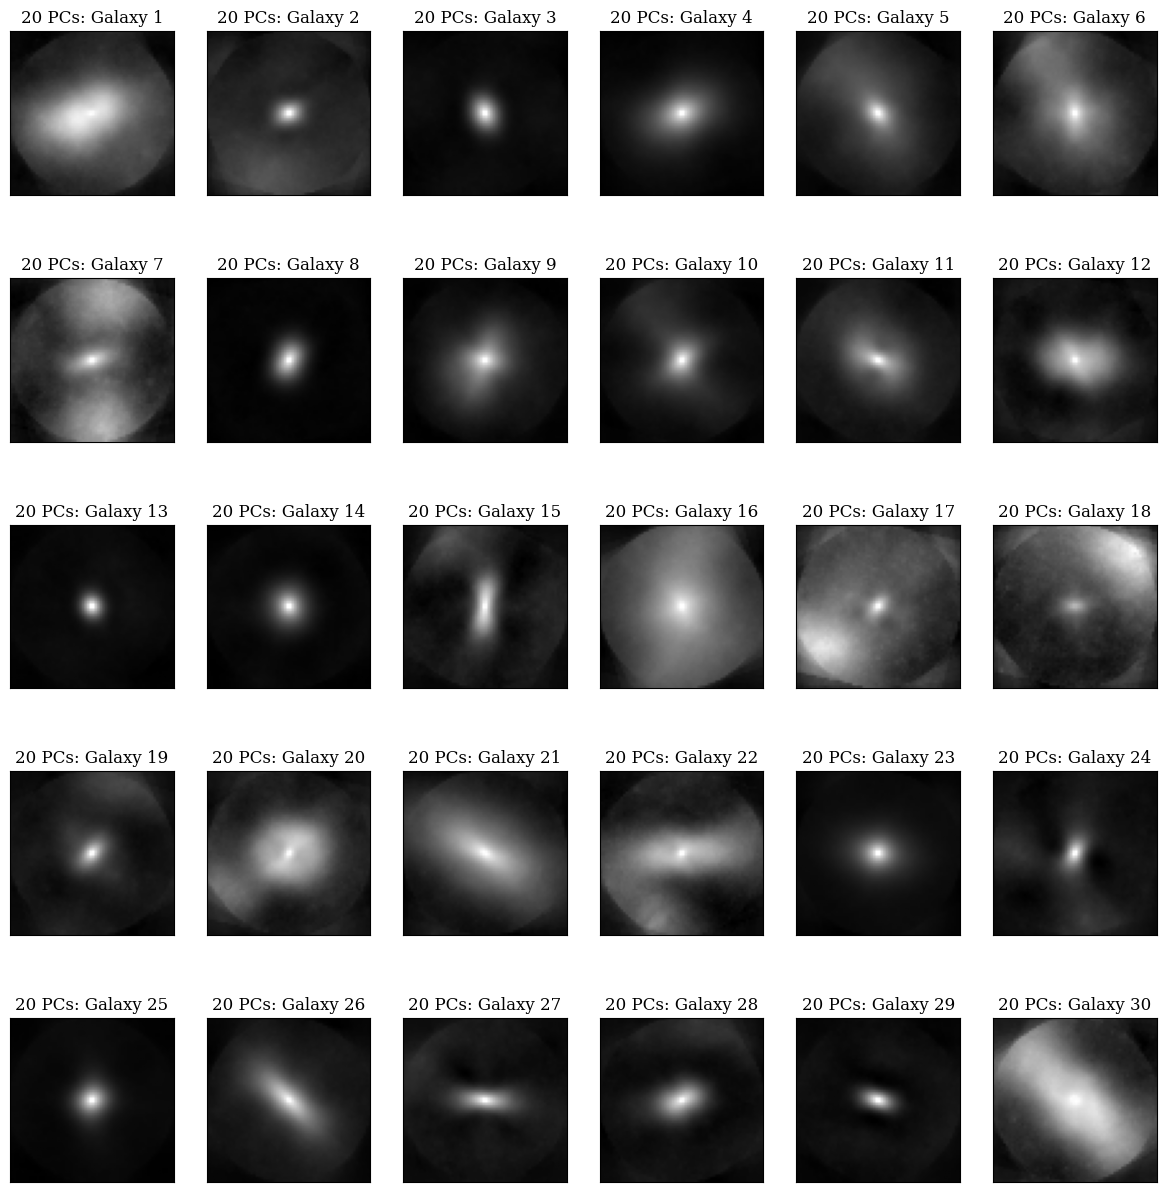

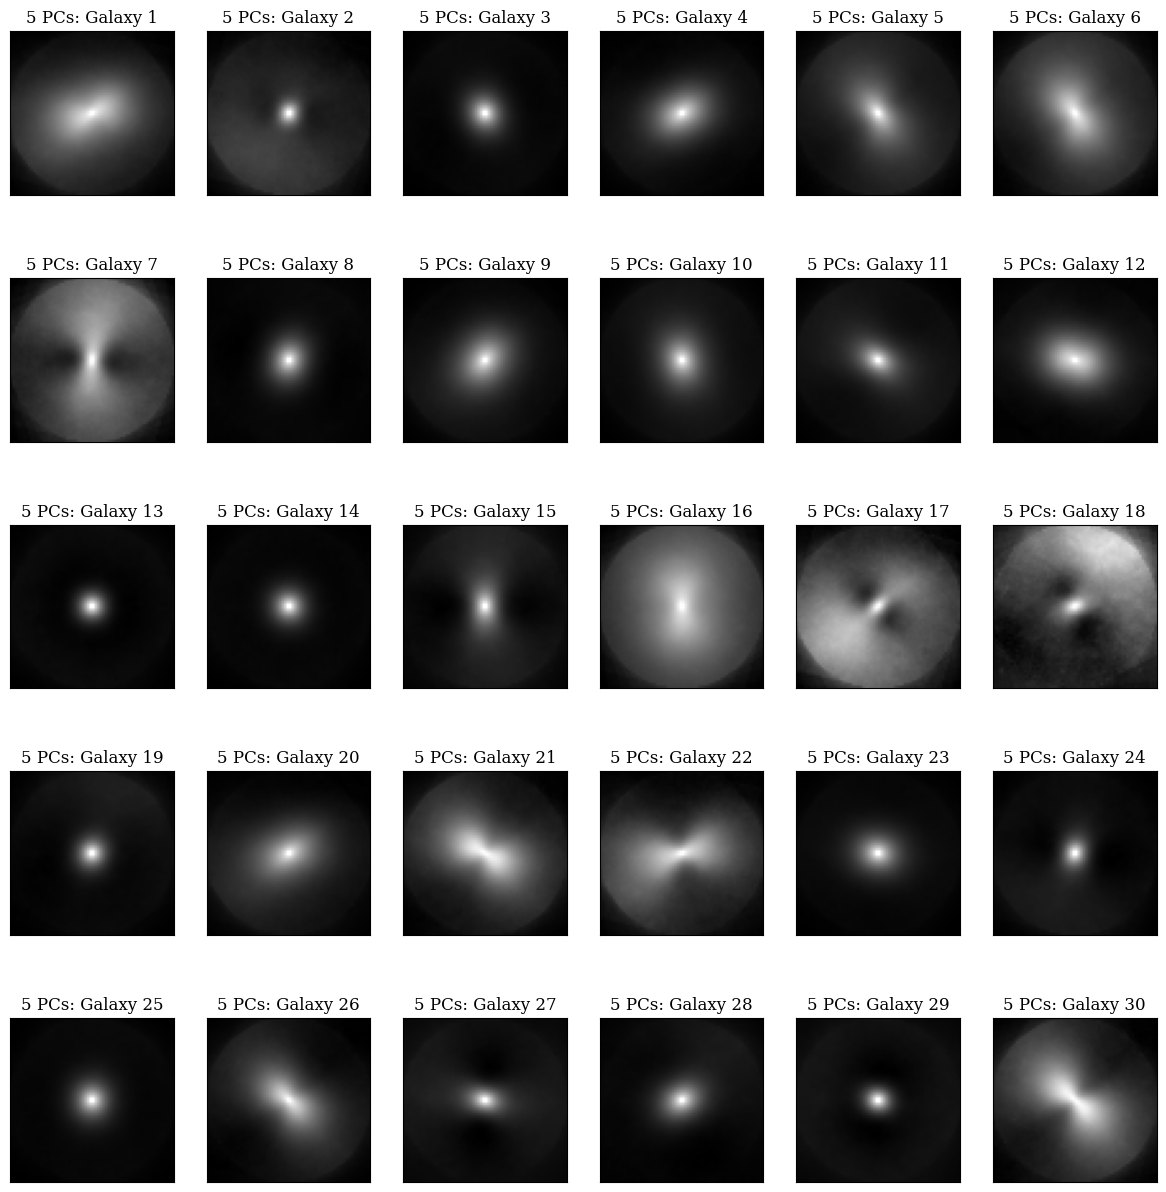

In [12]:
# First, look at some original images
plot_gallery(galaxy_images, ['Original Galaxy {}'.format(i + 1) for i in range(30)], 64, 64, 5, 6)

# Then the reconstructions
for n_pc in (50, 20, 5):
    plot_gallery(reconstructed[n_pc], ['{} PCs: Galaxy {}'.format(n_pc, i + 1) for i in range(30)], 64, 64, 5, 6)

The comparison shows how the images change when we reduce the dimension a lot.

**50 principal components.** With 50 components, which carry about 85% of the variance (the third dot), the reconstructed galaxies keep their main shapes. Elongated galaxies, such as Galaxy 15 and 21, keep their elongated profiles. Round galaxies keep their smooth light distributions.

**20 principal components.** With 20 components, which carry about 80% of the variance (the second dot), most galaxies keep their size, elongation and concentration. Round galaxies appear as smooth, centrally concentrated blobs, and elongated galaxies such as Galaxy 26 keep their shape. The fine structure is lost. Cutouts with bright neighbors or frame edges reconstruct poorly, because these features follow no common pattern. Galaxy 7, 17 and 18 show bright patches from their neighbors.

**5 principal components.** With 5 components, which carry about 67% of the variance (the first dot), most galaxies reduce to simple blobs. The elongated galaxies 21, 22, 26 and 30 show bow-tie shapes, which come from the quadrupole eigengalaxies 3 and 4. Galaxy 17 and 18 show a pinwheel that comes from the light of their bright neighbors, and the round center of Galaxy 18 looks elongated. This strong compression keeps only the overall brightness, the orientation and the rough shape.

The loss of information goes from the fine details to the basic structure. The early components carry the most variance and keep the large-scale shape. The number of components to keep is a choice between compression and accuracy.

## PCA as a Denoising Filter

The reconstructions look smoother than the originals. We now ask whether the dropped components hold noise.

PCA tends to separate coherent signal from random noise, because it keeps the directions of large variance. This property helps in astronomical imaging, where several noise sources act, such as photon noise, detector readout noise and atmospheric effects.

Consider how different types of features contribute to the principal components.

- **Coherent features.** Morphological structures that appear in many galaxies, such as bulges and disks, create correlated variations in the pixel values. These correlations form the early principal components, which describe these repeating structures efficiently.
- **Random noise.** Pixel-level noise has, by definition, no correlation between images. Each noise realization is unique. Its variance spreads over many later components and does not concentrate in the early ones.
- **Transient features.** Satellite galaxies, foreground stars and cosmic ray hits appear at random positions in different images. Unlike the central galaxy, which appears in each frame, these features do not create strong correlations in the covariance matrix. Consequently, they tend to appear in higher-order components.

The reconstructions agree with the last point for faint neighbors. They are weak at 20 components, and some return at 50 components (Galaxy 10, 19 and 24). Bright neighbors are an exception, because Galaxy 7, 17 and 18 show them already at 20 components.

We can therefore keep only the dominant principal components and so remove part of the noise. The coherent signal of the galaxy remains. The number of components to keep is a trade-off between noise suppression and signal preservation.

How well PCA removes noise depends on the signal-to-noise ratio of the data. Well-exposed images of bright galaxies show a clear separation between signal-dominated and noise-dominated components. For fainter galaxies near the detection limit, this separation is less distinct, and we must choose the truncation point with care.

## Storage Efficiency and Practical Considerations

Besides the removal of part of the noise, the reduction saves storage. We now count the storage savings of the principal component representation.

For our galaxy data set we have the following.

- Each galaxy needs $64 \times 64 = 4{,}096$ pixel values.
- The whole data set needs $N \times 4{,}096$ values for $N$ galaxies.

With $M$ principal components, we need to store the following.

1. The principal component basis $\mathbf{V}_M^T \in \mathbb{R}^{M \times 4096}$
2. The projection coefficients $\mathbf{Z} \in \mathbb{R}^{N \times M}$ for all galaxies
3. The mean galaxy $\overline{\mathbf{x}} \in \mathbb{R}^{4096}$

The total storage is $4096 M + N M + 4096 = 4096 (M + 1) + N M$ values. For a survey with 10,000 galaxies, more than our sample, we find the following.

- The original images need $10{,}000 \times 4{,}096 = 40{,}960{,}000$ values.
- With 50 components, PCA needs $4{,}096 \times 51 + 10{,}000 \times 50 = 708{,}896$ values, which is a reduction of 98.3%.
- With 20 components, PCA needs $4{,}096 \times 21 + 10{,}000 \times 20 = 286{,}016$ values, which is a reduction of 99.3%.

This compression helps even more for larger surveys, because the basis and the mean galaxy take a fixed number of values. For very many galaxies, the original storage divided by the PCA storage approaches $4096/M$, which is 82 for 50 components. The Vera Rubin Observatory Legacy Survey of Space and Time (LSST) will observe many more galaxies than any survey before.

PCA also makes the computation efficient. Many astronomical studies, such as the clustering of galaxies by morphology, need the similarity between galaxies. In the original 4,096-dimensional space, one similarity needs 4,096 operations. In the 50-dimensional PCA space, it needs only 50 operations once we have projected each galaxy onto the components. This is nearly two orders of magnitude less.

The compressed representation also helps machine learning. A classifier or a regression model trained on the 4,096 pixels often overfits because of the curse of dimensionality. The PCA coefficients form a smaller set of features that keeps the morphological variation. A model on these features has fewer weights, and this can lower the overfitting.

## Limits of PCA

PCA is a good method to analyze galaxy morphology, but we must know its limits to apply it well.

**Linearity constraint.** PCA finds only linear relationships in the data. It assumes that we can write the galaxies as linear combinations of the principal components. This works well for many morphological variations. Linear scaling and addition of components can describe elongation, size and brightness. Non-linear transformations such as rotations or complex changes of structure, however, may need many components to approximate what non-linear methods can describe more efficiently.

**Orthogonality requirement.** The principal components must be orthogonal. This can lead to components that mix several physical features (Section 10.9). It can also spread one feature over several components. Elongation is an example. Each galaxy has its own angle, so elongation uses the two orthogonal eigengalaxies 3 and 4, and no single component describes it. Both effects make a physical interpretation hard.

**Sensitivity to preprocessing.** The PCA results depend on the choices of the data preprocessing.

- **Centering.** The way we center the galaxies in their cutouts affects which spatial modes appear in the early components.
- **Scaling.** The relative scaling of the pixel values affects which features dominate the variance.
- **Background subtraction.** Residual background gradients can dominate the early components if we do not remove them well.

The goals of the analysis must guide these choices. For morphological studies, careful centering of the galaxies and careful background subtraction are necessary. For detection or classification, some preprocessing choices can remove useful information.

**Sensitivity to outliers.** PCA maximizes variance, so a few extreme images can shape the components (Section 10.9). Bright neighbors and frame edges are not part of the galaxies, yet they carry variance. The bright patches in the reconstructions of Galaxy 7, 17 and 18 are an example.

**Several populations.** Galaxies fall into types such as ellipticals and disks. PCA gives one set of components for all of them (Section 10.9). These components follow the largest total variance, which can differ from the main axis of each type.

**Global nature of components.** Each principal component is a global pattern over the whole image. Local features such as individual star-forming regions or tidal streams may be described poorly, unless they occur in the same way in many galaxies.

## Summary

In this tutorial we applied PCA to galaxy images. We went from the pixel space to a compact representation that keeps most of the variation. Our main lessons follow.

1. **Few components carry most of the variance.** The galaxy images are highly redundant, so a few components keep most of the variation.
2. **Components are ordered by variance.** The early components encode large-scale features of the images. Later components describe smaller details and noise.
3. **The reduced dimension is a choice.** PCA has no target and no prediction error. The variance of the dropped components equals the average squared reconstruction error, so it shows the trade-off between compression and accuracy.
4. **Denoising and storage.** PCA tends to separate coherent signal from random noise, and the coefficients need far less storage than the pixels.
5. **Components can be viewed.** For images, the principal components are images that we can look at, although they need not match a physical property.

PCA gives a compact description of high-dimensional data and shows which patterns dominate it. It has limits. It is linear, its components are orthogonal and global, and its results depend on the preprocessing. Outliers can shape its components, and it gives one set of components for all groups of objects. PCA is still a good first step in the exploration of a new data set.